# All imports

In [ ]:
!pip install mujoco

# Set up GPU rendering.
from google.colab import files
import distutils.util
import os
import subprocess
try:
  subprocess.run('nvidia-smi')
  use_GPU = True

except:
  use_GPU = False
  print(
      'Cannot communicate with GPU. ',
      'Make sure you are using a GPU Colab runtime. ',
      'Go to the Runtime menu and select Choose runtime type.')
if use_GPU:
  # Add an ICD config so that glvnd can pick up the Nvidia EGL driver.
  # This is usually installed as part of an Nvidia driver package, but the Colab
  # kernel doesn't install its driver via APT, and as a result the ICD is missing.
  # (https://github.com/NVIDIA/libglvnd/blob/master/src/EGL/icd_enumeration.md)
  NVIDIA_ICD_CONFIG_PATH = '/usr/share/glvnd/egl_vendor.d/10_nvidia.json'
  if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
    with open(NVIDIA_ICD_CONFIG_PATH, 'w') as f:
      f.write("""{
      "file_format_version" : "1.0.0",
      "ICD" : {
          "library_path" : "libEGL_nvidia.so.0"
      }
  }
  """)

  # Configure MuJoCo to use the EGL rendering backend (requires GPU)
  print('Setting environment variable to use GPU rendering:')
  %env MUJOCO_GL=egl
else:
  # Required for OSMesa OpenGL driver
  !apt-get update
  !apt-get install -y libosmesa6-dev libgl1-mesa-glx libglfw3

  print('Setting environment variable to use CPU rendering:')
  %env MUJOCO_GL=osmesa

# Check if installation was succesful.
try:
  print('Checking that the installation succeeded:')
  import mujoco
  mujoco.MjModel.from_xml_string('<mujoco/>')
except Exception as e:
  raise e from RuntimeError(
      'Something went wrong during installation. Check the shell output above '
      'for more information.\n'
      'If using a hosted Colab runtime, make sure you enable GPU acceleration '
      'by going to the Runtime menu and selecting "Choose runtime type".')

print('Installation successful.')

# Other imports and helper functions
import time
import itertools
import numpy as np

# Graphics and plotting.
print('Installing mediapy:')
!command -v ffmpeg >/dev/null || (apt update && apt install -y ffmpeg)
!pip install -q mediapy
import mediapy as media
import matplotlib.pyplot as plt

# More legible printing from numpy.
np.set_printoptions(precision=3, suppress=True, linewidth=100)

from IPython.display import clear_output
clear_output()


In [ ]:
!pip install dm_control
from dm_control import mjcf
clear_output()

In [ ]:
from scipy.spatial.transform import Rotation
from matplotlib import pyplot as plt

# Simulation 1

In [ ]:
# 1. Root
root = mjcf.RootElement()

# 2. Assets
mesh = root.asset.add('mesh', name='Boat_Mesh', file='./RC_BOAT_2.STL', scale=[0.01, 0.01, 0.01])

grid_texture = root.asset.add('texture', name='Grid_Texture', type='2d', builtin='checker',
                              rgb1=[.1, .2, .3], rgb2=[.2, .3, .4],width=300, height=300, mark='edge',
                              markrgb=[.2, .3, .4])

grid_mataterial = root.asset.add('material', name='Grid_Material', texture=grid_texture,
                           texrepeat=[2, 2], texuniform=True, reflectance=.2, rgba=[1, 1, 1, 0.5])

# 3. World Body
root.worldbody.add('light', directional=True, diffuse=[.9, .9, .9], specular=[0.1, 0.1, 0.1],
                    pos=[0, 0, 5], dir=[0, 0, -1], castshadow=True)

root.worldbody.add('geom', name='ground', type='plane', size=[50, 50, 1],
                    material=grid_mataterial, friction=[.1], contype=0, conaffinity=0)

boat = root.worldbody.add('body', name='Boat', pos=[0, 0, 1], euler=[0, 90, 0])
boat.add('freejoint')
boat.add('geom', type='mesh', mesh=mesh)

rudder = boat.add('body', name='Rudder', pos=[0, 0, -0.5], gravcomp=0)
rudder.add('geom', type='capsule', size=[0.05], fromto=[0, 0.125, 0, 0, 0.225, 0], density=1e-3)
rudder_joint = rudder.add('joint', name='Rudder_Hinge', axis=[0, 0, 1], pos=[0, 0.125, 0], range=[-90, 90], damping=0.5)
thrust_site = rudder.add('site', name='Thrust_Site', pos=[0, 0.225, 0], type='box', size=[0.05, 0.05, 0.05])


root.actuator.add('position', name="Rudder_Angle", joint=rudder_joint, ctrlrange=[-1.57, 1.57], kp=10)
root.actuator.add('motor', name='Thruster', site=thrust_site, ctrlrange=[-36, 36], gear=[0, 100, 0, 0, 0, 0])

model_xml = root.to_xml_string(filename_with_hash=False)

model = mujoco.MjModel.from_xml_string(model_xml)
boat_com_pos = model.body('Boat').ipos

weight = boat.add('body', name='Weight', pos=boat_com_pos)
weight.add('geom', type='box', size=[0.1, 0.1, 0.1], pos=[0, 0, -0.3], density=100000)

model_xml = root.to_xml_string(filename_with_hash=False)
model = mujoco.MjModel.from_xml_string(model_xml)

data = mujoco.MjData(model)
renderer = mujoco.Renderer(model)

In [ ]:
duration = 10   # (seconds)
framerate = 30  # (Hz)

height = 480
width = 640
n_frames = int(duration*framerate)
frames = np.zeros((n_frames, height, width, 3), dtype=np.uint8)

mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)


with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_frames):
    while data.time < i/framerate:
      depth = data.body('Boat').xipos[2]
      data.ctrl[0] = 0
      data.ctrl[1] = 0
      if depth < 0:
        data.body('Boat').xfrc_applied[2] = 50000*np.abs(depth)*1*1*9.81 - 10000*data.body('Boat').cvel[5]

      data.body('Boat').xfrc_applied[3] =  -3000*data.body('Boat').cvel[0]
      data.body('Boat').xfrc_applied[4] =  -3000*data.body('Boat').cvel[1]
      data.body('Boat').xfrc_applied[5] =  -3000*data.body('Boat').cvel[2]

      mujoco.mj_step(model, data)

    renderer.update_scene(data)
    pixels = renderer.render()
    frames[i] = pixels

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


# Simulation 2

In [ ]:
# 1. Root
root = mjcf.RootElement()

# 2. Assets
mesh = root.asset.add('mesh', name='Boat_Mesh', file='./RC_BOAT_2.STL', scale=[0.01, 0.01, 0.01])

grid_texture = root.asset.add('texture', name='Grid_Texture', type='2d', builtin='checker',
                              rgb1=[.1, .2, .3], rgb2=[.2, .3, .4],width=300, height=300, mark='edge',
                              markrgb=[.2, .3, .4])

grid_mataterial = root.asset.add('material', name='Grid_Material', texture=grid_texture,
                           texrepeat=[2, 2], texuniform=True, reflectance=.2, rgba=[1, 1, 1, 0.5])

# 3. World Body
root.worldbody.add('light', directional=True, diffuse=[.9, .9, .9], specular=[0.1, 0.1, 0.1],
                    pos=[0, 0, 5], dir=[0, 0, -1], castshadow=True)

root.worldbody.add('geom', name='ground', type='plane', size=[50, 50, 1],
                    material=grid_mataterial, friction=[.1], contype=0, conaffinity=0)

boat = root.worldbody.add('body', name='Boat', pos=[0, 0, 3], euler=[90, 0, 0])
boat.add('freejoint')
boat.add('geom', type='mesh', mesh=mesh)

rudder = boat.add('body', name='Rudder', pos=[0, 0, -0.5], gravcomp=0)
rudder.add('geom', type='capsule', size=[0.05], fromto=[0, 0.125, 0, 0, 0.225, 0], density=1e-3)
rudder_joint = rudder.add('joint', name='Rudder_Hinge', axis=[0, 0, 1], pos=[0, 0.125, 0], range=[-90, 90], damping=0.5)
thrust_site = rudder.add('site', name='Thrust_Site', pos=[0, 0.225, 0], type='box', size=[0.05, 0.05, 0.05])


root.actuator.add('position', name="Rudder_Angle", joint=rudder_joint, ctrlrange=[-1.57, 1.57], kp=10)
root.actuator.add('motor', name='Thruster', site=thrust_site, ctrlrange=[-36, 36], gear=[0, 100, 0, 0, 0, 0])

model_xml = root.to_xml_string(filename_with_hash=False)

model = mujoco.MjModel.from_xml_string(model_xml)
boat_com_pos = model.body('Boat').ipos

weight = boat.add('body', name='Weight', pos=boat_com_pos)
weight.add('geom', type='box', size=[0.1, 0.1, 0.1], pos=[0, 0, -0.3], density=100000)

model_xml = root.to_xml_string(filename_with_hash=False)
model = mujoco.MjModel.from_xml_string(model_xml)

data = mujoco.MjData(model)
renderer = mujoco.Renderer(model)

In [ ]:
duration = 10   # (seconds)
framerate = 30  # (Hz)

height = 480
width = 640
n_frames = int(duration*framerate)
frames = np.zeros((n_frames, height, width, 3), dtype=np.uint8)

mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)


with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_frames):
    while data.time < i/framerate:
      depth = data.body('Boat').xipos[2]
      data.ctrl[0] = 0
      data.ctrl[1] = 0
      if depth < 0:
        data.body('Boat').xfrc_applied[2] = 50000*np.abs(depth)*1*1*9.81 - 10000*data.body('Boat').cvel[5]

      data.body('Boat').xfrc_applied[3] =  -3000*data.body('Boat').cvel[0]
      data.body('Boat').xfrc_applied[4] =  -3000*data.body('Boat').cvel[1]
      data.body('Boat').xfrc_applied[5] =  -3000*data.body('Boat').cvel[2]

      mujoco.mj_step(model, data)

    renderer.update_scene(data)
    pixels = renderer.render()
    frames[i] = pixels

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


# Simulation 3

In [ ]:
# 1. Root
root = mjcf.RootElement()

# 2. Assets
mesh = root.asset.add('mesh', name='Boat_Mesh', file='./RC_BOAT_2.STL', scale=[0.01, 0.01, 0.01])

grid_texture = root.asset.add('texture', name='Grid_Texture', type='2d', builtin='checker',
                              rgb1=[.1, .2, .3], rgb2=[.2, .3, .4],width=300, height=300, mark='edge',
                              markrgb=[.2, .3, .4])

grid_mataterial = root.asset.add('material', name='Grid_Material', texture=grid_texture,
                           texrepeat=[2, 2], texuniform=True, reflectance=.2, rgba=[1, 1, 1, 0.5])

# 3. World Body
root.worldbody.add('light', directional=True, diffuse=[.9, .9, .9], specular=[0.1, 0.1, 0.1],
                    pos=[0, 0, 5], dir=[0, 0, -1], castshadow=True)

root.worldbody.add('geom', name='ground', type='plane', size=[50, 50, 1],
                    material=grid_mataterial, friction=[.1], contype=0, conaffinity=0)

boat = root.worldbody.add('body', name='Boat', pos=[0, 0, 1], euler=[0, 0, 180])
boat.add('freejoint')
boat.add('geom', type='mesh', mesh=mesh)

rudder = boat.add('body', name='Rudder', pos=[0, 0, -0.5], gravcomp=0)
rudder.add('geom', type='capsule', size=[0.05], fromto=[0, 0.125, 0, 0, 0.225, 0], density=1e-3)
rudder_joint = rudder.add('joint', name='Rudder_Hinge', axis=[0, 0, 1], pos=[0, 0.125, 0], range=[-90, 90], damping=0.5)
thrust_site = rudder.add('site', name='Thrust_Site', pos=[0, 0.225, 0], type='box', size=[0.05, 0.05, 0.05])


root.actuator.add('motor', name='Thruster', site=thrust_site, ctrlrange=[-36, 36], gear=[0, 100, 0, 0, 0, 0])
root.actuator.add('position', name="Rudder_Angle", joint=rudder_joint, ctrlrange=[-1.57, 1.57], kp=10)

model_xml = root.to_xml_string(filename_with_hash=False)

model = mujoco.MjModel.from_xml_string(model_xml)
boat_com_pos = model.body('Boat').ipos

weight = boat.add('body', name='Weight', pos=boat_com_pos)
weight.add('geom', type='box', size=[0.1, 0.1, 0.1], pos=[0, 0, -0.3], density=100000)

model_xml = root.to_xml_string(filename_with_hash=False)
model = mujoco.MjModel.from_xml_string(model_xml)

data = mujoco.MjData(model)
renderer = mujoco.Renderer(model)

In [ ]:
duration = 10   # (seconds)
framerate = 30  # (Hz)

height = 480
width = 640
n_frames = int(duration*framerate)
frames = np.zeros((n_frames, height, width, 3), dtype=np.uint8)

mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)


with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_frames):
    while data.time < i/framerate:
      depth = data.body('Boat').xipos[2]
      data.ctrl[1] = 0.2
      data.ctrl[0] = -20
      if depth < 0:
        data.body('Boat').xfrc_applied[2] = 50000*np.abs(depth)*1*1*9.81 - 10000*data.body('Boat').cvel[5]

      data.body('Boat').xfrc_applied[3] =  -3000*data.body('Boat').cvel[0]
      data.body('Boat').xfrc_applied[4] =  -3000*data.body('Boat').cvel[1]
      data.body('Boat').xfrc_applied[5] =  -3000*data.body('Boat').cvel[2]

      mujoco.mj_step(model, data)

    renderer.update_scene(data)
    pixels = renderer.render()
    frames[i] = pixels

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


# Simulation 4

In [ ]:
# 1. Root
root = mjcf.RootElement()

# 2. Assets
mesh = root.asset.add('mesh', name='Boat_Mesh', file='./RC_BOAT_2.STL', scale=[0.01, 0.01, 0.01])

grid_texture = root.asset.add('texture', name='Grid_Texture', type='2d', builtin='checker',
                              rgb1=[.1, .2, .3], rgb2=[.2, .3, .4],width=300, height=300, mark='edge',
                              markrgb=[.2, .3, .4])

grid_mataterial = root.asset.add('material', name='Grid_Material', texture=grid_texture,
                           texrepeat=[2, 2], texuniform=True, reflectance=.2, rgba=[1, 1, 1, 0.1])

# 3. World Body
root.worldbody.add('light', directional=True, diffuse=[.9, .9, .9], specular=[0.1, 0.1, 0.1],
                    pos=[0, 0, 5], dir=[0, 0, -1], castshadow=True)

root.worldbody.add('geom', name='ground', type='plane', size=[50, 50, 1],
                    material=grid_mataterial, friction=[.1], contype=0, conaffinity=0)

boat = root.worldbody.add('body', name='Boat', pos=[0, 0, 1], euler=[0, 0, 180])
boat.add('freejoint')
boat.add('geom', type='mesh', mesh=mesh)

rudder = boat.add('body', name='Rudder', pos=[0, 0, -0.5], gravcomp=0)
rudder.add('geom', type='capsule', size=[0.05], fromto=[0, 0.125, 0, 0, 0.225, 0], density=1e-3)
rudder_joint = rudder.add('joint', name='Rudder_Hinge', axis=[0, 0, 1], pos=[0, 0.125, 0], range=[-90, 90], damping=0.5)
thrust_site = rudder.add('site', name='Thrust_Site', pos=[0, 0.225, 0], type='box', size=[0.05, 0.05, 0.05])


root.actuator.add('motor', name='Thruster', site=thrust_site, ctrlrange=[-36, 36], gear=[0, 100, 0, 0, 0, 0])
root.actuator.add('position', name="Rudder_Angle", joint=rudder_joint, ctrlrange=[-1.57, 1.57], kp=10)

model_xml = root.to_xml_string(filename_with_hash=False)

model = mujoco.MjModel.from_xml_string(model_xml)
boat_com_pos = model.body('Boat').ipos

weight = boat.add('body', name='Weight', pos=boat_com_pos)
weight.add('geom', type='box', size=[0.1, 0.1, 0.1], pos=[0, 0, -0.3], density=100000)

model_xml = root.to_xml_string(filename_with_hash=False)
model = mujoco.MjModel.from_xml_string(model_xml)

data = mujoco.MjData(model)
renderer = mujoco.Renderer(model)

In [ ]:
duration = 10   # (seconds)
framerate = 30  # (Hz)

height = 480
width = 640
n_frames = int(duration*framerate)
frames = np.zeros((n_frames, height, width, 3), dtype=np.uint8)

mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)

pos_ref = np.array([3,3])

Kp=2
Kd=2
Kp_theta=1
Kd_theta=1

var_view = []

with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_frames):
    while data.time < i/framerate:
      depth = data.body('Boat').xipos[2]

      if depth < 0:
        data.body('Boat').xfrc_applied[2] = 50000*np.abs(depth)*1*1*9.81 - 10000*data.body('Boat').cvel[5]

      data.body('Boat').xfrc_applied[3] =  -3000*data.body('Boat').cvel[0]
      data.body('Boat').xfrc_applied[4] =  -3000*data.body('Boat').cvel[1]
      data.body('Boat').xfrc_applied[5] =  -3000*data.body('Boat').cvel[2]


      xipos = data.body('Boat').xipos
      cvel = data.body('Boat').cvel

      Fx = Kp*(pos_ref[0] - xipos[0]) - Kd*cvel[3]
      Fy = Kp*(pos_ref[1] - xipos[1]) - Kd*cvel[4]

      #Outer Loop
      thrust_des = np.sqrt(Fx**2 + Fy**2)
      theta_des = np.arctan2(Fy, Fx) - np.pi/2

      quat = data.body('Boat').xquat
      euler = Rotation.from_quat(quat, scalar_first=True).as_euler('xyz')

      torque_des = Kp_theta*(theta_des - euler[2]) - Kd_theta*cvel[2]


      l = 1 #Boat lenght

      u_2 =  np.arcsin(-2*np.clip(torque_des, a_min=-thrust_des*(l/2), a_max=thrust_des*(l/2))/(l*thrust_des))
      u_1 = np.clip(thrust_des, a_min=0, a_max=10)

      data.ctrl[0] = u_1
      data.ctrl[1] = u_2

      var_view.append([theta_des, euler[2]])

      mujoco.mj_step(model, data)

    renderer.update_scene(data)
    pixels = renderer.render()
    frames[i] = pixels

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


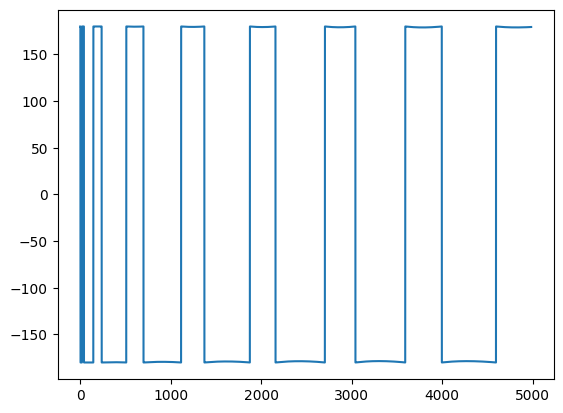

In [ ]:
var_arr = np.array(var_view)
plt.plot(np.rad2deg(var_arr[:, 1]))
plt.show()


# Simulation 5

In [ ]:
# 1. Root
root = mjcf.RootElement()

# 2. Assets
mesh = root.asset.add('mesh', name='Boat_Mesh', file='./RC_BOAT_2.STL', scale=[0.01, 0.01, 0.01])

grid_texture = root.asset.add('texture', name='Grid_Texture', type='2d', builtin='checker',
                              rgb1=[.1, .2, .3], rgb2=[.2, .3, .4],width=300, height=300, mark='edge',
                              markrgb=[.2, .3, .4])

grid_mataterial = root.asset.add('material', name='Grid_Material', texture=grid_texture,
                           texrepeat=[2, 2], texuniform=True, reflectance=.2, rgba=[1, 1, 1, 0.1])

# 3. World Body
root.worldbody.add('light', directional=True, diffuse=[.9, .9, .9], specular=[0.1, 0.1, 0.1],
                    pos=[0, 0, 5], dir=[0, 0, -1], castshadow=True)

root.worldbody.add('geom', name='ground', type='plane', size=[50, 50, 1],
                    material=grid_mataterial, friction=[.1], contype=0, conaffinity=0)

boat = root.worldbody.add('body', name='Boat', pos=[5, 0, 1], euler=[0, 0, 0])
boat.add('freejoint')
boat.add('geom', type='mesh', mesh=mesh)

rudder = boat.add('body', name='Rudder', pos=[0, 0, -0.5], gravcomp=0)
rudder.add('geom', type='capsule', size=[0.05], fromto=[0, 0.125, 0, 0, 0.225, 0], density=1e-3)
rudder_joint = rudder.add('joint', name='Rudder_Hinge', axis=[0, 0, 1], pos=[0, 0.125, 0], range=[-90, 90], damping=0.5)
thrust_site = rudder.add('site', name='Thrust_Site', pos=[0, 0.225, 0], type='box', size=[0.05, 0.05, 0.05])


root.actuator.add('motor', name='Thruster', site=thrust_site, ctrlrange=[-36, 36], gear=[0, 100, 0, 0, 0, 0])
root.actuator.add('position', name="Rudder_Angle", joint=rudder_joint, ctrlrange=[-1.57, 1.57], kp=10)

model_xml = root.to_xml_string(filename_with_hash=False)

model = mujoco.MjModel.from_xml_string(model_xml)
boat_com_pos = model.body('Boat').ipos

weight = boat.add('body', name='Weight', pos=boat_com_pos)
weight.add('geom', type='box', size=[0.1, 0.1, 0.1], pos=[0, 0, -0.3], density=100000)

model_xml = root.to_xml_string(filename_with_hash=False)
model = mujoco.MjModel.from_xml_string(model_xml)

data = mujoco.MjData(model)
renderer = mujoco.Renderer(model)

In [ ]:
duration = 20   # (seconds)
framerate = 30  # (Hz)

height = 480
width = 640
n_frames = int(duration*framerate)
frames = np.zeros((n_frames, height, width, 3), dtype=np.uint8)

mujoco.mj_resetDataKeyframe(model, data, 0)
mujoco.mj_forward(model, data)

pos_ref = np.array([3,3])

Kp=0.1
Kd=5
Kp_theta=5
Kd_theta=1

var_view = []

with mujoco.Renderer(model, height, width) as renderer:
  for i in range(n_frames):
    while data.time < i/framerate:
      depth = data.body('Boat').xipos[2]

      if depth < 0:
        data.body('Boat').xfrc_applied[2] = 50000*np.abs(depth)*1*1*9.81 - 10000*data.body('Boat').cvel[5]

      data.body('Boat').xfrc_applied[3] =  -3000*data.body('Boat').cvel[0]
      data.body('Boat').xfrc_applied[4] =  -3000*data.body('Boat').cvel[1]
      data.body('Boat').xfrc_applied[5] =  -3000*data.body('Boat').cvel[2]


      xipos = data.body('Boat').xipos
      cvel = data.body('Boat').cvel

      Fx = Kp*(pos_ref[0] - xipos[0]) - Kd*cvel[3]
      Fy = Kp*(pos_ref[1] - xipos[1]) - Kd*cvel[4]

      #Outer Loop
      thrust_des = np.sqrt(Fx**2 + Fy**2)
      theta_des = np.arctan2(Fy, Fx) + np.pi/2

      quat = data.body('Boat').xquat
      euler = Rotation.from_quat(quat, scalar_first=True).as_euler('xyz')

      torque_des = Kp_theta*(theta_des - euler[2]) - Kd_theta*cvel[2]


      l = 1 #Boat lenght

      u_2 =  np.arcsin(-2*np.clip(torque_des, a_min=-thrust_des*(l/2), a_max=thrust_des*(l/2))/(l*thrust_des))
      u_1 = thrust_des

      data.ctrl[0] = -u_1*0
      data.ctrl[1] =  u_2*0

      var_view.append(theta_des)

      mujoco.mj_step(model, data)

    renderer.update_scene(data)
    pixels = renderer.render()
    frames[i] = pixels

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


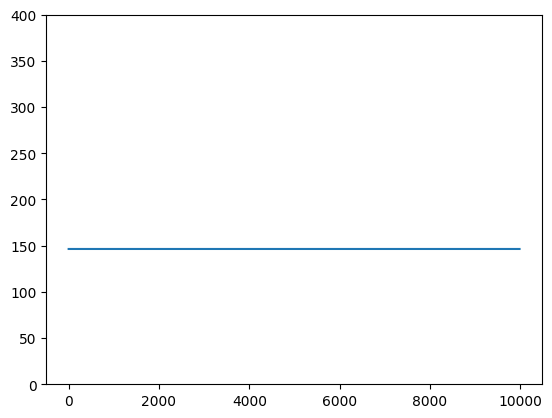

In [ ]:
var_arr = np.array(var_view)
plt.plot(np.rad2deg(var_arr))
plt.ylim(0, 400)

plt.show()
